In [1]:
# Assignment 3 - Load DistilBERT for embedding extraction

import torch
from transformers import AutoTokenizer, AutoModel

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
embed_model = AutoModel.from_pretrained(model_name)
embed_model.eval()

print("Loaded:", model_name)
print("CUDA available:", torch.cuda.is_available())

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded: distilbert-base-uncased
CUDA available: False


In [2]:
# Emotion word list and embedding extraction

import torch
import numpy as np

emotion_words = [
    "happy", "joy", "excited",
    "sad", "angry", "fear",
    "love", "hate", "surprise"
]

def get_word_embedding(word):
    inputs = tokenizer(word, return_tensors="pt")
    with torch.no_grad():
        outputs = embed_model(**inputs)
    # Use CLS token embedding (first token)
    cls_embedding = outputs.last_hidden_state[:, 0, :]
    return cls_embedding.squeeze().numpy()

embeddings = {}
for word in emotion_words:
    embeddings[word] = get_word_embedding(word)

print("Extracted embeddings for:", list(embeddings.keys()))
print("Embedding dimension:", embeddings["happy"].shape[0])

Extracted embeddings for: ['happy', 'joy', 'excited', 'sad', 'angry', 'fear', 'love', 'hate', 'surprise']
Embedding dimension: 768


In [3]:
# Cosine similarity between emotion word embeddings

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

words_list = list(embeddings.keys())
matrix = np.stack([embeddings[w] for w in words_list], axis=0)

sim = cosine_similarity(matrix)

sim_df = pd.DataFrame(sim, index=words_list, columns=words_list)
sim_df

,happy,joy,excited,sad,angry,fear,love,hate,surprise
happy,1.000000,0.977076,0.981615,0.979741,0.978548,0.970401,0.982094,0.960708,0.973894
joy,0.977076,1.000000,0.967863,0.967693,0.961428,0.952628,0.967616,0.954531,0.959681
excited,0.981615,0.967863,1.000000,0.968209,0.978044,0.973426,0.971091,0.957162,0.980444
sad,0.979741,0.967693,0.968209,1.000000,0.978313,0.976982,0.978788,0.969351,0.964387
angry,0.978548,0.961428,0.978044,0.978313,1.000000,0.984347,0.977568,0.982949,0.973404
fear,0.970401,0.952628,0.973426,0.976982,0.984347,1.000000,0.982919,0.977608,0.978361
love,0.982094,0.967616,0.971091,0.978788,0.977568,0.982919,1.000000,0.973897,0.973254
hate,0.960708,0.954531,0.957162,0.969351,0.982949,0.977608,0.973897,1.000000,0.954915
surprise,0.973894,0.959681,0.980444,0.964387,0.973404,0.978361,0.973254,0.954915,1.000000


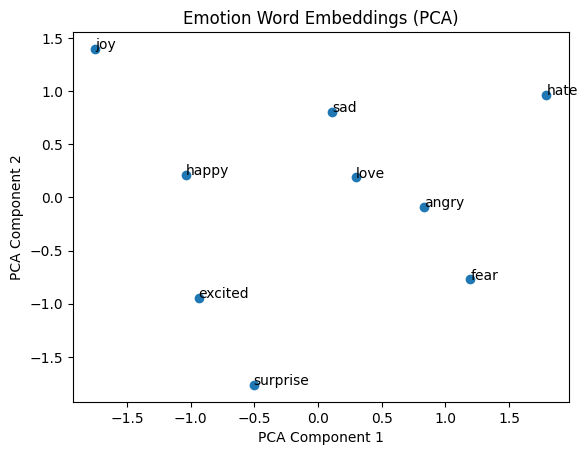

In [4]:
# PCA visualization of emotion word embeddings

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
reduced = pca.fit_transform(matrix)

plt.figure()
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(words_list):
    plt.text(reduced[i, 0], reduced[i, 1], word)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Emotion Word Embeddings (PCA)")
plt.show()